In [4]:
# ================================================
# 2. DATA PREPROCESSING
# ================================================

# 1. Libraries

from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and splitting
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings("ignore")


# 2. Configuration

RANDOM_STATE = 42
N_SPLITS = 5

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid")


# 3. Load Dataset

# Update DATA_PATH if your project uses a different directory structure.

possible_paths = [
    Path("../Data/Raw/insurance_claim_fraud_dataset.csv"),
    Path("Data/Raw/insurance_claim_fraud_dataset.csv"),
    Path("../data/raw/insurance_claim_fraud_dataset.csv"),
    Path("data/raw/insurance_claim_fraud_dataset.csv"),
    Path("insurance_claim_fraud_dataset.csv")
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Update DATA_PATH with the correct CSV location."
    )

df = pd.read_csv(DATA_PATH)

# 4. Initial Verification

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["fraudulent"].value_counts(dropna=False))

Dataset Shape: (100000, 62)


,claim_id,policy_id,customer_id,customer_name,claim_date,incident_date,claim_status,claim_amount,approved_amount,deductible,claim_duration_days,age,gender,marital_status,occupation,annual_income,education_level,credit_score,years_with_company,previous_claims,policy_type,policy_start_date,policy_duration_years,premium_amount,coverage_amount,deductible_plan,payment_method,policy_active,incident_type,accident_severity,incident_location,weather_condition,police_report,witnesses,injuries,hospital_visit,property_damage,vehicle_damage,vehicle_make,vehicle_model,vehicle_year,vehicle_age,mileage,vehicle_value,ownership_type,suspicious_documents,claim_submitted_at_night,multiple_claims_last_year,delayed_reporting,inconsistent_statements,gps_location_match,repair_shop_verified,identity_verified,claim_history_risk,fraud_risk_score,repair_cost,medical_cost,towing_cost,rental_vehicle_cost,total_loss,payout_amount,fraudulent
0,CLM-0000001,POL-75682867,CUST-231932,Allison Hill,2024-09-01,2024-08-25,Denied,7909.060,0.000,250.000,9,32,Female,Single,Accountant,60104.190,Bachelor,514,10,1,Liability Only,2019-12-15,6,503.120,248130.770,Low ($250),Auto-Debit,Yes,Multi-Vehicle Collision,Moderate,Highway,Clear,Yes,2,0,No,Yes,Side Impact,Tesla,Model S,2019,5,71378,23747.940,Leased,Yes,No,No,Yes,No,Yes,Yes,Yes,Medium,38,7044.740,0.000,0.000,864.320,No,0.000,Yes
1,CLM-0000002,POL-79778859,CUST-356508,Noah Rhodes,2022-02-08,2022-02-06,Denied,12676.050,11408.440,1000.000,11,25,Male,Married,Software Engineer,83225.500,Master,301,5,1,Uninsured Motorist,2020-02-05,2,2080.600,232398.130,"High ($1,000)",Auto-Debit,No,Single Vehicle Collision,Total Loss,Parking Lot,Icy,Yes,4,0,No,No,Side Impact,Chevrolet,Cruze,2013,9,84996,14241.530,Owned,No,No,No,No,No,Yes,No,Yes,Medium,2,12370.730,0.000,149.520,155.800,Yes,11676.050,No
2,CLM-0000003,POL-93122310,CUST-894824,Angie Henderson,2025-10-29,2025-10-29,Approved,14930.340,14930.340,1000.000,42,29,Male,Widowed,Sales Representative,94971.020,Doctorate,398,7,0,Liability Only,2023-02-12,3,3543.140,144706.530,"High ($1,000)",Bank Transfer,Yes,Single Vehicle Collision,Major,Suburban,Rainy,Yes,2,0,No,No,Side Impact,BMW,X5,2009,16,139830,5820.160,Owned,No,No,No,No,No,Yes,Yes,Yes,Low,0,3002.830,10517.480,335.540,1074.490,No,13930.340,No
3,CLM-0000004,POL-63892568,CUST-668550,Daniel Wagner,2021-11-14,2021-11-14,Pending,1018.980,917.080,1000.000,2,79,Male,Single,Construction Worker,121099.250,Master,558,6,0,Liability Only,2020-01-06,3,1577.650,68590.130,"High ($1,000)",Credit Card,Yes,Theft,Minor,Urban,Rainy,No,1,0,No,No,Rollover,Toyota,Camry,2021,0,19649,45000.000,Financed,No,No,No,No,No,Yes,Yes,Yes,Low,0,1018.980,0.000,0.000,0.000,No,18.980,No
4,CLM-0000005,POL-50657662,CUST-792517,Cristian Santos,2024-10-02,2024-10-01,Denied,20924.380,18831.940,250.000,16,41,Male,Married,Manager,114735.500,High School,500,5,2,Personal Injury Protection,2023-07-27,3,1894.660,33082.370,Low ($250),Credit Card,Yes,Multi-Vehicle Collision,Major,Rural,Foggy,No,1,2,Yes,No,NaN,Chevrolet,Tahoe,2021,3,25883,30666.240,Financed,No,No,Yes,No,No,Yes,Yes,Yes,Medium,3,20205.570,0.000,202.140,516.670,No,20674.380,No



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 62 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   claim_id                   100000 non-null  str    
 1   policy_id                  100000 non-null  str    
 2   customer_id                100000 non-null  str    
 3   customer_name              100000 non-null  str    
 4   claim_date                 100000 non-null  str    
 5   incident_date              100000 non-null  str    
 6   claim_status               100000 non-null  str    
 7   claim_amount               100000 non-null  float64
 8   approved_amount            100000 non-null  float64
 9   deductible                 100000 non-null  float64
 10  claim_duration_days        100000 non-null  int64  
 11  age                        100000 non-null  int64  
 12  gender                     100000 non-null  str    
 13  marital_status     

In [5]:
# ==========================================
# STEP 1: INITIAL FEATURE SELECTION
# ==========================================

df_model = df.copy()

# Target
target = "fraudulent"

# Potential target leakage or post-decision features
leakage_features = [
    "fraud_risk_score",
    "claim_status",
    "approved_amount",
    "payout_amount",
    "repair_cost",
    "medical_cost",
    "towing_cost",
    "rental_vehicle_cost",
    "claim_duration_days",
    "total_loss"
]

# Investigation / verification-stage features
investigation_features = [
    "suspicious_documents",
    "inconsistent_statements",
    "gps_location_match",
    "repair_shop_verified",
    "identity_verified",
    "vehicle_damage",
    "claim_history_risk"
]

# Identifiers and personal information
identifier_features = [
    "claim_id",
    "policy_id",
    "customer_id",
    "customer_name"
]

# Preserve customer ID for group-aware splitting
groups = df_model["customer_id"].copy()

# Remove only columns that actually exist
columns_to_drop = [
    col for col in (
        leakage_features +
        investigation_features +
        identifier_features
    )
    if col in df_model.columns
]

df_model = df_model.drop(columns=columns_to_drop)

print("Original dataset shape:", df.shape)
print("Modelling dataset shape:", df_model.shape)

print("\nRemoved columns:")
print(columns_to_drop)

print("\nRemaining target distribution:")
print(df_model[target].value_counts())

Original dataset shape: (100000, 62)
Modelling dataset shape: (100000, 41)

Removed columns:
['fraud_risk_score', 'claim_status', 'approved_amount', 'payout_amount', 'repair_cost', 'medical_cost', 'towing_cost', 'rental_vehicle_cost', 'claim_duration_days', 'total_loss', 'suspicious_documents', 'inconsistent_statements', 'gps_location_match', 'repair_shop_verified', 'identity_verified', 'vehicle_damage', 'claim_history_risk', 'claim_id', 'policy_id', 'customer_id', 'customer_name']

Remaining target distribution:
fraudulent
No     79958
Yes    20042
Name: count, dtype: int64


In [6]:
# ==========================================
# STEP 2: FEATURE AND TARGET SEPARATION
# ==========================================

X = df_model.drop(columns=[target]).copy()

y = df_model[target].map({
    "No": 0,
    "Yes": 1
})

# Validate target encoding
assert y.notna().all(), "Unexpected or missing target values!"
assert set(y.unique()) == {0, 1}, "Target must contain only 0 and 1."

# Align customer groups with the modelling rows
groups = groups.loc[X.index]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget encoding:")
print(y.value_counts().sort_index())

print("\nTarget distribution:")
print(y.value_counts(normalize=True).sort_index())

print("\nMissing target values:", y.isna().sum())

X shape: (100000, 40)
y shape: (100000,)

Target encoding:
fraudulent
0    79958
1    20042
Name: count, dtype: int64

Target distribution:
fraudulent
0   0.800
1   0.200
Name: proportion, dtype: float64

Missing target values: 0


In [7]:
# ==========================================
# STEP 3: DATE FEATURE ENGINEERING
# ==========================================

# Convert date columns
date_columns = [
    "claim_date",
    "incident_date",
    "policy_start_date"
]

for col in date_columns:
    if col in X.columns:
        X[col] = pd.to_datetime(X[col], errors="coerce")


# Claim submission date features
if "claim_date" in X.columns:
    X["claim_month"] = X["claim_date"].dt.month
    X["claim_day_of_week"] = X["claim_date"].dt.dayofweek


# Reporting delay
if {"claim_date", "incident_date"}.issubset(X.columns):
    X["reporting_delay_days"] = (
        X["claim_date"] - X["incident_date"]
    ).dt.days

    # Negative reporting delay is invalid
    X.loc[
        X["reporting_delay_days"] < 0,
        "reporting_delay_days"
    ] = np.nan


# Policy tenure at claim submission
if {"claim_date", "policy_start_date"}.issubset(X.columns):
    X["policy_tenure_years"] = (
        (X["claim_date"] - X["policy_start_date"]).dt.days / 365.25
    )

    # Negative policy tenure is invalid
    X.loc[
        X["policy_tenure_years"] < 0,
        "policy_tenure_years"
    ] = np.nan


# Recalculate vehicle age at claim
if {"claim_date", "vehicle_year"}.issubset(X.columns):
    X["vehicle_age_at_claim"] = (
        X["claim_date"].dt.year - X["vehicle_year"]
    )

    # Impossible vehicle ages are invalid
    X.loc[
        X["vehicle_age_at_claim"] < 0,
        "vehicle_age_at_claim"
    ] = np.nan

    # Remove the original age column because EDA identified inconsistencies
    X = X.drop(columns=["vehicle_age"], errors="ignore")


# Remove raw dates after feature extraction
X = X.drop(
    columns=date_columns,
    errors="ignore"
)

print("Feature engineering completed.")
print("Feature count:", X.shape[1])

display(X.head())

Feature engineering completed.
Feature count: 41


,claim_amount,deductible,age,gender,marital_status,occupation,annual_income,education_level,credit_score,years_with_company,previous_claims,policy_type,policy_duration_years,premium_amount,coverage_amount,deductible_plan,payment_method,policy_active,incident_type,accident_severity,incident_location,weather_condition,police_report,witnesses,injuries,hospital_visit,property_damage,vehicle_make,vehicle_model,vehicle_year,mileage,vehicle_value,ownership_type,claim_submitted_at_night,multiple_claims_last_year,delayed_reporting,claim_month,claim_day_of_week,reporting_delay_days,policy_tenure_years,vehicle_age_at_claim
0,7909.060,250.000,32,Female,Single,Accountant,60104.190,Bachelor,514,10,1,Liability Only,6,503.120,248130.770,Low ($250),Auto-Debit,Yes,Multi-Vehicle Collision,Moderate,Highway,Clear,Yes,2,0,No,Yes,Tesla,Model S,2019,71378,23747.940,Leased,No,No,Yes,9,6,7.000,4.715,5.000
1,12676.050,1000.000,25,Male,Married,Software Engineer,83225.500,Master,301,5,1,Uninsured Motorist,2,2080.600,232398.130,"High ($1,000)",Auto-Debit,No,Single Vehicle Collision,Total Loss,Parking Lot,Icy,Yes,4,0,No,No,Chevrolet,Cruze,2013,84996,14241.530,Owned,No,No,No,2,1,2.000,2.010,9.000
2,14930.340,1000.000,29,Male,Widowed,Sales Representative,94971.020,Doctorate,398,7,0,Liability Only,3,3543.140,144706.530,"High ($1,000)",Bank Transfer,Yes,Single Vehicle Collision,Major,Suburban,Rainy,Yes,2,0,No,No,BMW,X5,2009,139830,5820.160,Owned,No,No,No,10,2,0.000,2.710,16.000
3,1018.980,1000.000,79,Male,Single,Construction Worker,121099.250,Master,558,6,0,Liability Only,3,1577.650,68590.130,"High ($1,000)",Credit Card,Yes,Theft,Minor,Urban,Rainy,No,1,0,No,No,Toyota,Camry,2021,19649,45000.000,Financed,No,No,No,11,6,0.000,1.856,0.000
4,20924.380,250.000,41,Male,Married,Manager,114735.500,High School,500,5,2,Personal Injury Protection,3,1894.660,33082.370,Low ($250),Credit Card,Yes,Multi-Vehicle Collision,Major,Rural,Foggy,No,1,2,Yes,No,Chevrolet,Tahoe,2021,25883,30666.240,Financed,No,Yes,No,10,2,1.000,1.185,3.000


In [8]:
# ==========================================
# STEP 4: DATA CLEANING AND FEATURE IDENTIFICATION
# ==========================================

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Check for unsupported data types
identified_features = numerical_features + categorical_features
unidentified_features = [
    col for col in X.columns
    if col not in identified_features
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Unidentified features:", len(unidentified_features))
print("Total features:", X.shape[1])

if unidentified_features:
    print("\nUnidentified columns:")
    print(unidentified_features)

    raise TypeError(
        "Some features have unsupported data types. "
        "Review and convert them before proceeding."
    )


# Missing-value overview
missing_values = (
    X.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_values = missing_values[missing_values > 0]

print("\nMissing Values:")
display(missing_values.to_frame("Missing Count"))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# Duplicate feature rows
print("\nDuplicate feature rows:", X.duplicated().sum())

Numerical features: 20
Categorical features: 21
Unidentified features: 0
Total features: 41

Missing Values:


,Missing Count
vehicle_age_at_claim,6137



Numerical Features:
['claim_amount', 'deductible', 'age', 'annual_income', 'credit_score', 'years_with_company', 'previous_claims', 'policy_duration_years', 'premium_amount', 'coverage_amount', 'witnesses', 'injuries', 'vehicle_year', 'mileage', 'vehicle_value', 'claim_month', 'claim_day_of_week', 'reporting_delay_days', 'policy_tenure_years', 'vehicle_age_at_claim']

Categorical Features:
['gender', 'marital_status', 'occupation', 'education_level', 'policy_type', 'deductible_plan', 'payment_method', 'policy_active', 'incident_type', 'accident_severity', 'incident_location', 'weather_condition', 'police_report', 'hospital_visit', 'property_damage', 'vehicle_make', 'vehicle_model', 'ownership_type', 'claim_submitted_at_night', 'multiple_claims_last_year', 'delayed_reporting']

Duplicate feature rows: 0


In [9]:
# ==========================================
# STEP 5: TRAIN-TEST SPLIT
# ==========================================

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Use the first fold as the held-out test set
train_idx, test_idx = next(
    cv.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()


# Split verification
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

customer_overlap = set(groups_train) & set(groups_test)

print("\nCustomer overlap:", len(customer_overlap))

assert len(customer_overlap) == 0, (
    "Customer leakage detected between training and testing sets!"
)

assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

print("\nTrain-test split completed successfully.")

Training shape: (80000, 41)
Testing shape: (20000, 41)

Training target distribution:
fraudulent
0    63966
1    16034
Name: count, dtype: int64
fraudulent
0   0.800
1   0.200
Name: proportion, dtype: float64

Testing target distribution:
fraudulent
0    15992
1     4008
Name: count, dtype: int64
fraudulent
0   0.800
1   0.200
Name: proportion, dtype: float64

Customer overlap: 0

Train-test split completed successfully.


In [10]:
# ==========================================
# STEP 6: PREPROCESSING PIPELINE
# ==========================================

# Numerical preprocessing
numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])


# Categorical preprocessing
# Support both newer and older scikit-learn versions
try:
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        one_hot_encoder
    )
])


# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessing pipeline configured successfully.")

Preprocessing pipeline configured successfully.


In [11]:
# ==========================================
# STEP 7: FIT AND APPLY TRANSFORMATIONS
# ==========================================

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using training-fitted transformations
X_test_processed = preprocessor.transform(X_test)


# Obtain transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)

print("Transformed feature count:", len(feature_names))

print("\nFirst 20 transformed features:")
print(feature_names[:20])

assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert X_train_processed.shape[1] == len(feature_names)

print("\nFeature transformation completed successfully.")

Training matrix shape: (80000, 145)
Testing matrix shape: (20000, 145)
Transformed feature count: 145

First 20 transformed features:
['numerical__claim_amount' 'numerical__deductible' 'numerical__age'
 'numerical__annual_income' 'numerical__credit_score'
 'numerical__years_with_company' 'numerical__previous_claims'
 'numerical__policy_duration_years' 'numerical__premium_amount'
 'numerical__coverage_amount' 'numerical__witnesses' 'numerical__injuries'
 'numerical__vehicle_year' 'numerical__mileage' 'numerical__vehicle_value'
 'numerical__claim_month' 'numerical__claim_day_of_week'
 'numerical__reporting_delay_days' 'numerical__policy_tenure_years'
 'numerical__vehicle_age_at_claim']

Feature transformation completed successfully.


Training class counts:
Legitimate claims (0): 63966
Fraudulent claims (1): 16034

Fraud percentage in training data: 20.04 %

XGBoost scale_pos_weight: 3.989


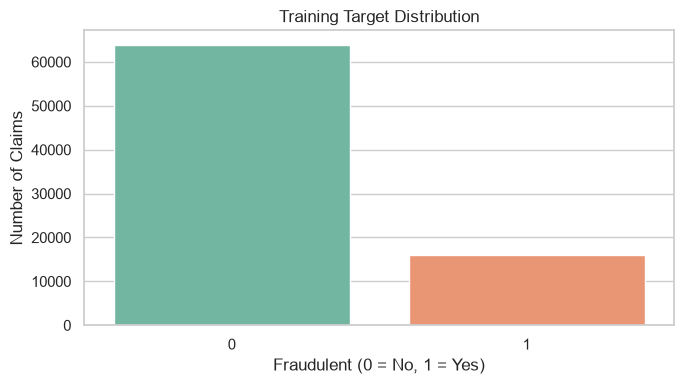

In [12]:
# ==========================================
# STEP 8: CLASS IMBALANCE ANALYSIS
# ==========================================

class_counts = y_train.value_counts().sort_index()

negative_count = class_counts[0]
positive_count = class_counts[1]

scale_pos_weight = negative_count / positive_count

print("Training class counts:")
print("Legitimate claims (0):", negative_count)
print("Fraudulent claims (1):", positive_count)

print("\nFraud percentage in training data:",
      round(y_train.mean() * 100, 2), "%")

print("\nXGBoost scale_pos_weight:", round(scale_pos_weight, 3))


# Visualize training target distribution
plt.figure(figsize=(7, 4))

sns.countplot(
    x=y_train,
    hue=y_train,
    palette="Set2",
    legend=False
)

plt.title("Training Target Distribution")
plt.xlabel("Fraudulent (0 = No, 1 = Yes)")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

In [13]:
# ==========================================
# STEP 9: FINAL PREPROCESSING SUMMARY
# ==========================================

print("=" * 50)
print("       PREPROCESSING SUMMARY")
print("=" * 50)

print("\nOriginal dataset:", df.shape)
print("Feature matrix:", X.shape)

print("\nTraining samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Transformed features:", len(feature_names))

print("\nTraining fraud rate:",
      round(y_train.mean() * 100, 2), "%")

print("Testing fraud rate:",
      round(y_test.mean() * 100, 2), "%")

print("\nCustomer overlap:", len(customer_overlap))

print("\nMissing values after transformation:")

if hasattr(X_train_processed, "tocsr"):
    train_missing = np.isnan(X_train_processed.data).sum()
    test_missing = np.isnan(X_test_processed.data).sum()
else:
    train_missing = np.isnan(X_train_processed).sum()
    test_missing = np.isnan(X_test_processed).sum()

print("Training:", train_missing)
print("Testing:", test_missing)

print("\nPreprocessing completed.")
print("Ready for model development.")

       PREPROCESSING SUMMARY

Original dataset: (100000, 62)
Feature matrix: (100000, 41)

Training samples: 80000
Testing samples: 20000

Numerical features: 20
Categorical features: 21
Transformed features: 145

Training fraud rate: 20.04 %
Testing fraud rate: 20.04 %

Customer overlap: 0

Missing values after transformation:
Training: 0
Testing: 0

Preprocessing completed.
Ready for model development.


In [15]:
# ==========================================
# STEP 10: SAVE PROCESSED DATA
# ==========================================

from pathlib import Path
from scipy.sparse import csr_matrix, save_npz
import joblib
import json

# Create output directory
PROCESSED_DIR = Path("../Data/Processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


# Save feature matrices
save_npz(
    PROCESSED_DIR / "X_train.npz",
    csr_matrix(X_train_processed)
)

save_npz(
    PROCESSED_DIR / "X_test.npz",
    csr_matrix(X_test_processed)
)


# Save target arrays
np.save(
    PROCESSED_DIR / "y_train.npy",
    y_train.to_numpy(dtype=np.int8)
)

np.save(
    PROCESSED_DIR / "y_test.npy",
    y_test.to_numpy(dtype=np.int8)
)


# Save customer groups
groups_train.to_csv(
    PROCESSED_DIR / "groups_train.csv",
    index=False
)

groups_test.to_csv(
    PROCESSED_DIR / "groups_test.csv",
    index=False
)


# Save fitted preprocessor
joblib.dump(
    preprocessor,
    PROCESSED_DIR / "preprocessor.joblib"
)


# Save feature names
with open(
    PROCESSED_DIR / "feature_names.json",
    "w"
) as f:
    json.dump(feature_names.tolist(), f, indent=4)


print("=" * 45)
print("PROCESSED DATA SAVED")
print("=" * 45)

for file in PROCESSED_DIR.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

PROCESSED DATA SAVED
feature_names.json - 6.03 KB
groups_test.csv - 253.92 KB
groups_train.csv - 1015.64 KB
preprocessor.joblib - 10.27 KB
X_test.npz - 1437.99 KB
X_train.npz - 5745.06 KB
y_test.npy - 19.66 KB
y_train.npy - 78.25 KB
